# Retail Customer Analysis Summative Lab
## Understanding Customer Behavior Across Store Locations

### Introduction

This summative lab bridges the concepts and techniques learned throughout the course with their practical application to a real-world industry scenario. You will step into the role of a junior data analyst for a retail company and apply your skills to evaluate customer behavior, satisfaction, and promotional impacts. By following the outlined process, you will gain experience in experimental design, statistical testing, and actionable decision-making.

Your task is not only to conduct the analysis but also to reflect on how these techniques help solve real-world problems that businesses face daily.

By completing this lab, you will have:
- Practiced designing and executing statistical analyses in a real-world scenario.
- Reinforced your understanding of test selection and assumptions.
- Applied statistical results to business decision-making.
- Developed skills in communicating insights effectively through visualizations and reports.

### Business Scenario Questions:
Imagine you are a junior data analyst working for a retail company that operates stores in three distinct regions: City Center, Suburb, and Rural. Your manager has tasked you with analyzing customer behavior and preferences across these locations. The goal is to help the company answer two key questions:
1. Do customer spending patterns, satisfaction levels, and product preferences differ across store locations?
2. Do promotional periods result in significantly higher spending compared to non-promotional periods?

Spending Across Location:

- Business-relevant MDE: Absolute difference in spending of 15% or more
- Justification: This represents enough of a difference to warrant location-specific strategies (inventory, staffing, etc.)


Ratings Across Locations:

- Business-relevant MDE: 1.0 point difference between locations
- Justification: On a 10-point scale, a one point difference is noticeable and actionable for customer service improvements

Promotional Spending:

- Business-relevant MDE: A $15 increase from non-promotional periods
- Justification: Promotional costs typically reduce margins by ~15-20%. Need at least 25% increase in spending to justify promotional costs. This aligns with industry standards for promotional ROI

Your task involves designing and conducting an analysis using the provided dataset to derive actionable insights. You will apply statistical concepts and techniques such as experimental design, test selection, hypothesis testing, and result interpretation. This process mimics real-world industry scenarios where junior analysts evaluate business performance using data.

The data focuses on four variables:
- Amount spent by customers (in dollars)
- Customer satisfaction ratings (scale of 1 to 10)
- Product category preferences (Electronics, Clothing, Groceries)
- Purchase type (Promotional vs. Non-Promotional)

Your analysis will inform decision-making around marketing strategies, store operations, and promotional campaigns.

### Setup

In this cell, import all the libraries you'll need for your analysis. Consider which libraries you'll need for:
- Data manipulation
- Statistical analysis
- Data visualization

In [1]:
# Import relevant libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import scikit_posthocs as sp


### Part 1: Experimental Design

#### 1.1 Hypothesis Formulation

For each of the following analyses, state your null and alternative hypotheses in both statistical and plain language:

1. Spending across store locations
2. Customer satisfaction across locations
3. Promotional vs non-promotional spending
4. Product category preferences across locations


**Spending across store locations**

*H₀: μ_spending(City Center) = μ_spending(Suburb) = μ_spending(Rural)*

*H₁: At least one location's mean spending differs from the others*

H₀ — Average customer spending is the same across all three store locations.

H₁ — Average customer spending differs for at least one location.

Business-relevant MDE: An absolute difference in spending of 15% or more, since anything smaller isn't large enough to justify location-specific inventory or staffing strategies.

**Customer satisfaction across locations**

*H₀: μ_satisfaction(City Center) = μ_satisfaction(Suburb) = μ_satisfaction(Rural)*

*H₁: At least one location's mean satisfaction rating differs from the others*

H₀ — Average customer satisfaction ratings do not differ across store locations.

H₁ — Average customer satisfaction ratings differ for at least one location.

Business-relevant MDE: A 1.0 point difference on the 10-point scale, since this is the smallest gap that is noticeable and actionable for customer service improvements.

**Promotional vs. non-promotional spending**

*H₀: μ_spending(Promotional) ≤ μ_spending(Non-Promotional)*

*H₁: μ_spending(Promotional) > μ_spending(Non-Promotional)*

H₀ — Spending during promotional periods is not higher than spending during non-promotional periods.

H₁ — Spending during promotional periods is higher than spending during non-promotional periods.

Business-relevant MDE: A $15 increase over non-promotional spending, since promotional costs typically reduce margins by 15–20%, so the increase needs to be large enough to justify that cost.

Note: This is a one-tailed (directional) hypothesis, since the business question specifically asks whether promotions lead to higher spending, not merely different spending.

**Product category preferences across locations**

*H₀: Product category preference is independent of store location — the distribution of purchases across Electronics, Clothing, and Groceries is the same regardless of location.*

*H₁: Product category preference is not independent of store location — the distribution of category purchases differs by location.*

H₀ — Customers prefer the same mix of product categories no matter which store location they shop at.

H₁ — Preferred product category depends on which store location a customer shops at.




**Reflective Question: Explain the concept of Minimum Detectable Effect (MDE) and why it is important.**


**Minimal Detectable Effect** is the smallest effect size that a study is designed to relliably detect. It is set before the analysis, based on what magnitude of difference would actually be meaningful to the business.

**Why it matters**
* *Statistical significance is not the same as business sigificance. With a large enough sample size, even a trivially small and practically meaningless difference could produce a significant p-value. A test might reject a null hypothesis while the actual effect size is too small to matter operationally. MDE anchors the analysis to a threshold thats actually worth acting on.*
* *It connects the analysis back to the decision. Defining the MDE up front forces one to ask 'ho big of a differnece would change what we do?' before seeing the results, which prevents post-hoc rationalizing whatever number comes out pf the test.


*for our data a 15% absolute spending difference across locations is small enough to reflect meaningful behavioral differences, but large enough to be worth restructuring inventory or staffing by location.
A difference of 1.0(out of 10) across the locations is the smallest gap considered "noticeable" to customers and actionable for service teams.
A 15% increase in promotional spending is tied directly to the fact that promotions cut margins by roughly 15–20%, so the spending lift has to clear a real cost hurdle to be worth running the promotion at all.*

### Part 2: Data Exploration

#### 2.1 Load and Examine the Dataset

Load the dataset and perform initial data quality checks:
- Check for missing values
- Examine data types
- Look for inconsistencies
- Generate summary statistics

In [3]:
# Load Data
df = pd.read_csv('retail_store_customer_data.csv')

print ('rows:', df.shape[0])
print ('colmns:', df.shape[1])
df.head(10)

rows: 1500
colmns: 5


,Store_Location,Customer_Satisfaction,Product_Category,Purchase_Type,Amount_Spent
0,Rural,5.6,Groceries,Non-Promotional,40.45
1,City Center,9.7,Clothing,Promotional,53.20
2,Rural,4.4,Electronics,Non-Promotional,42.77
3,Rural,4.2,Clothing,Promotional,42.08
4,City Center,9.3,Clothing,Non-Promotional,84.25
5,City Center,8.9,Clothing,Non-Promotional,97.51
6,Rural,5.3,Groceries,Non-Promotional,46.21
7,Suburb,5.3,Clothing,Non-Promotional,47.91
8,Rural,8.2,Electronics,Non-Promotional,49.46
9,Rural,3.4,Clothing,Promotional,38.32


In [4]:
#Datatypes
df.dtypes

Store_Location               str
Customer_Satisfaction    float64
Product_Category             str
Purchase_Type                str
Amount_Spent             float64
dtype: object

In [7]:
# Missing values
df.isna().sum()

Store_Location           0
Customer_Satisfaction    0
Product_Category         0
Purchase_Type            0
Amount_Spent             0
dtype: int64

In [9]:
# Duplicated rows
df.duplicated().sum()

np.int64(0)

In [10]:
# Check for data inconsistencies 
for col in ["Store_Location", "Product_Category", "Purchase_Type"]:
    print(col, df[col].unique())

Store_Location <StringArray>
['Rural', 'City Center', 'Suburb']
Length: 3, dtype: str
Product_Category <StringArray>
['Groceries', 'Clothing', 'Electronics']
Length: 3, dtype: str
Purchase_Type <StringArray>
['Non-Promotional', 'Promotional']
Length: 2, dtype: str


In [11]:
#  Summary statistics 
df.describe()

,Customer_Satisfaction,Amount_Spent
count,1500.00000,1500.000000
mean,6.99520,59.915973
std,1.65286,19.551829
min,1.00000,15.550000
25%,5.80000,44.170000
50%,7.00000,58.015000
75%,8.20000,72.582500
max,10.00000,128.130000


**Category counts will be is in later tests**

In [13]:
df["Store_Location"].value_counts()



Store_Location
City Center    520
Suburb         492
Rural          488
Name: count, dtype: int64

*The store location records are fairly balanced with a spread of about 32 records*

In [14]:
df["Purchase_Type"].value_counts()


Purchase_Type
Promotional        888
Non-Promotional    612
Name: count, dtype: int64

*Promotional products are relatively more, with a relative difference of about 276 records*

In [15]:
df["Product_Category"].value_counts()

Product_Category
Electronics    583
Groceries      464
Clothing       453
Name: count, dtype: int64

*Fairly balanced with a spread of about 130 records*

#### 2.2 Data Visualizations

Create visualizations to understand the distribution of key variables:
- Spending patterns across locations
- Satisfaction ratings distribution
- Product category preferences
- Promotional vs non-promotional spending

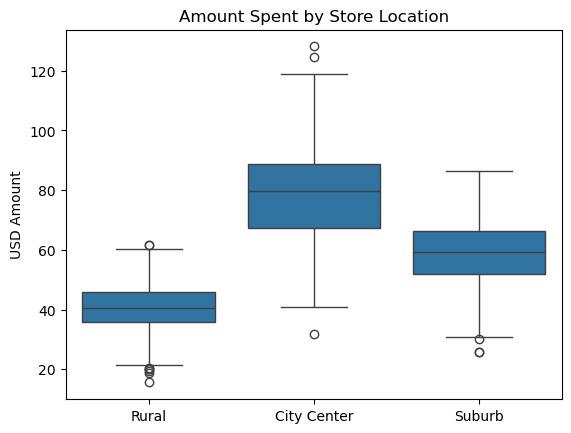

In [25]:
# 1. Spending patterns across locations
sns.boxplot(
    data=df, 
    x="Store_Location", 
    y="Amount_Spent"
    )

plt.title("Amount Spent by Store Location")
plt.xlabel(None)
plt.ylabel("USD Amount")
plt.show()

**Finding:** *City Center transactions have the highest spending, with a median of about $80,followed by Suburb at a median of about $60, then Rural as the lowest with a median of about $40.*

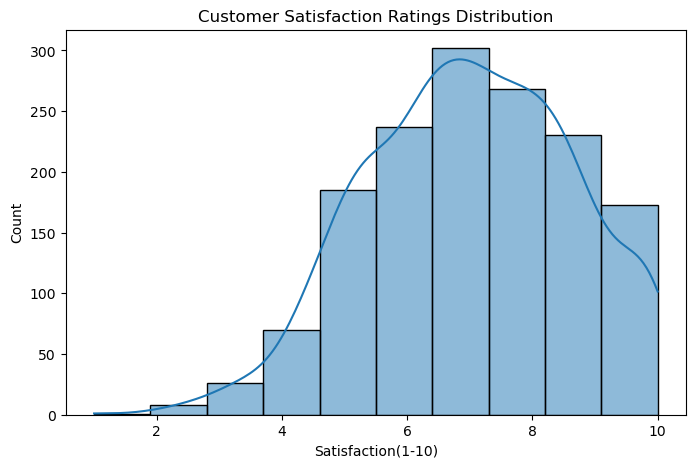

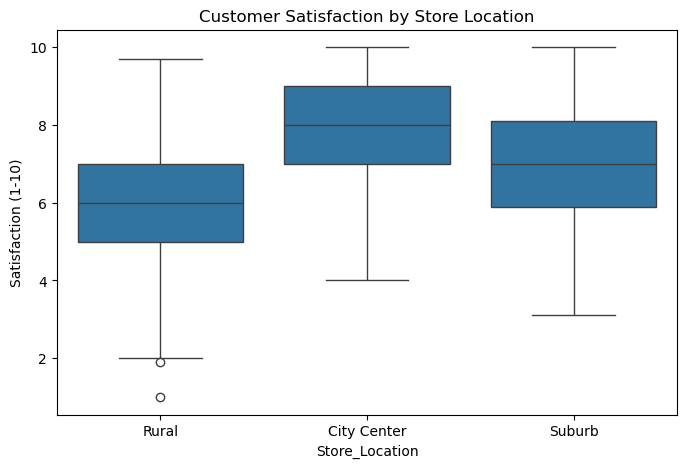

In [30]:
# Satisfaction ratings 
# Overall
plt.figure(figsize=(8,5))

sns.histplot(
    data=df, 
    x="Customer_Satisfaction", 
    bins=10, 
    kde=True
    )

plt.title("Customer Satisfaction Ratings Distribution")
plt.xlabel("Satisfaction(1-10)")
plt.show()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df, 
    x="Store_Location", 
    y="Customer_Satisfaction"
    )

plt.title("Customer Satisfaction by Store Location")
plt.ylabel("Satisfaction (1-10)")
plt.show()

**Finding:** *The average satisfaction rating for the company is about 7. City Center shows the highest satisfaction with a median of about 8, followed closely by Suburb with a median of about 7, then Rural with a median of about 6. There's an outlier case with a rating of 1.0 (perhaps a very dissatisfied customer).*


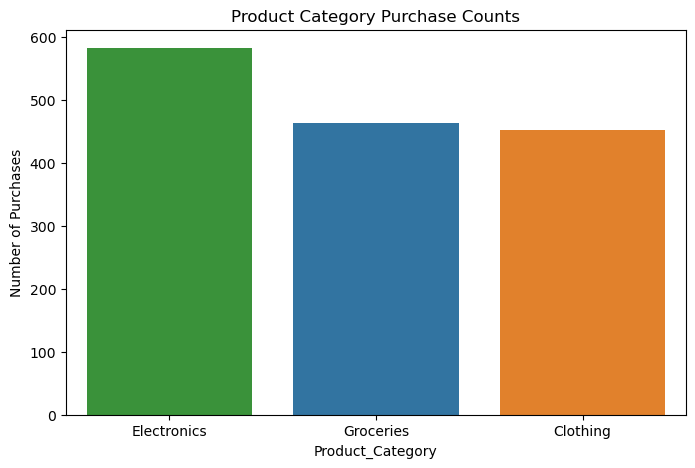

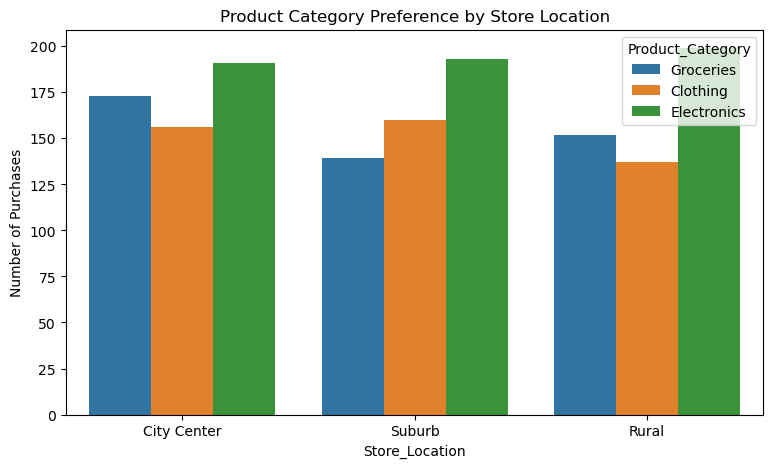

In [46]:
# 3. Product category preferences 
# Overall
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df, 
    x="Product_Category", 
    hue="Product_Category", 
    order=df["Product_Category"].value_counts().index,
    )

plt.title("Product Category Purchase Counts")
plt.ylabel("Number of Purchases")
plt.show()

# By location
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df, 
    x="Store_Location", 
    hue="Product_Category",
    order=order
)

plt.title("Product Category Preference by Store Location")
plt.ylabel("Number of Purchases")
plt.show()

*The most purchased item category was electronics both overall and in the various locations*

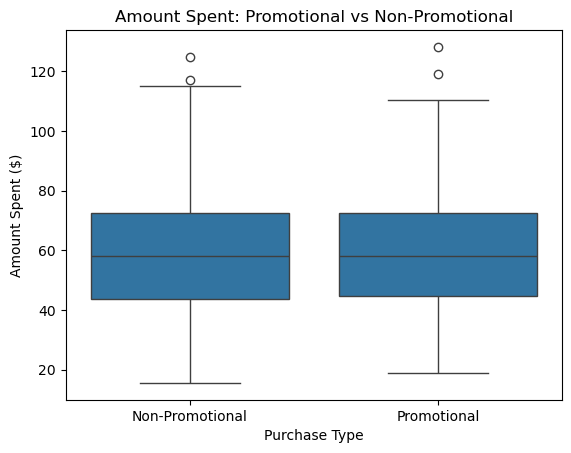

In [48]:
# 4. Promotional vs non-promotional spending
sns.boxplot(
    data=df, 
    x="Purchase_Type", 
    y="Amount_Spent"
    )

plt.title("Amount Spent: Promotional vs Non-Promotional")
plt.xlabel("Purchase Type")
plt.ylabel("Amount Spent ($)")
plt.show()

**Finding:** *Promotional and Non-Promotional spending look nearly identical, with medians of about $58 for both groups. This suggests that, on the surface, running a promotion doesn't seem to increase how much customers spend per transaction — we'll need the formal hypothesis test (and the $15 MDE) to confirm whether any difference is both statistically and practically significant.*

#### 2.3 Test Assumptions

Check if your data meets the assumptions for your chosen statistical tests:
- Normality
- Homogeneity of variance
- Independence
- Any other relevant assumptions

In [49]:
# Normality check (Shapiro-Wilk) — Amount_Spent by Store_Location
for loc in df["Store_Location"].unique():
    sample = df.loc[df["Store_Location"] == loc, "Amount_Spent"]
    stat, p = stats.shapiro(sample)
    print(f"{loc}: n={len(sample)}, W={stat:.4f}, p={p:.4g}")

Rural: n=488, W=0.9960, p=0.2594
City Center: n=520, W=0.9978, p=0.7536
Suburb: n=492, W=0.9940, p=0.05031


**Normality using Shapiro-Wilk**

In [50]:
# Normality check — Customer_Satisfaction by Store_Location
for loc in df["Store_Location"].unique():
    sample = df.loc[df["Store_Location"] == loc, "Customer_Satisfaction"]
    stat, p = stats.shapiro(sample)
    print(f"{loc}: n={len(sample)}, W={stat:.4f}, p={p:.4g}")

Rural: n=488, W=0.9965, p=0.373
City Center: n=520, W=0.9699, p=7.413e-09
Suburb: n=492, W=0.9890, p=0.0009248


In [51]:
# Normality check — Amount_Spent by Purchase_Type
for pt in df["Purchase_Type"].unique():
    sample = df.loc[df["Purchase_Type"] == pt, "Amount_Spent"]
    stat, p = stats.shapiro(sample)
    print(f"{pt}: n={len(sample)}, W={stat:.4f}, p={p:.4g}")

Non-Promotional: n=612, W=0.9754, p=1.253e-08
Promotional: n=888, W=0.9791, p=5.871e-10


**Homogeinity of variance**

In [52]:
# Homogeneity of variance (Levene's test)
groups_spend_loc = [df.loc[df["Store_Location"] == loc, "Amount_Spent"] for loc in df["Store_Location"].unique()]
print("Amount_Spent across locations:", stats.levene(*groups_spend_loc))

groups_sat_loc = [df.loc[df["Store_Location"] == loc, "Customer_Satisfaction"] for loc in df["Store_Location"].unique()]
print("Satisfaction across locations:", stats.levene(*groups_sat_loc))

groups_spend_promo = [df.loc[df["Purchase_Type"] == pt, "Amount_Spent"] for pt in df["Purchase_Type"].unique()]
print("Amount_Spent across promo type:", stats.levene(*groups_spend_promo))

Amount_Spent across locations: LeveneResult(statistic=np.float64(106.40980858330316), pvalue=np.float64(6.169093419924019e-44))
Satisfaction across locations: LeveneResult(statistic=np.float64(1.6154302575557304), pvalue=np.float64(0.19915148116430784))
Amount_Spent across promo type: LeveneResult(statistic=np.float64(0.38605478155178413), pvalue=np.float64(0.5344750353148945))


In [53]:
# Chi-square assumption check — expected cell counts for Location x Product_Category
ct = pd.crosstab(df["Store_Location"], df["Product_Category"])
chi2, p, dof, expected = stats.chi2_contingency(ct)
print("Observed:\n", ct)
print("\nExpected:\n", pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1))
print("\nMinimum expected count:", expected.min())

Observed:
 Product_Category  Clothing  Electronics  Groceries
Store_Location                                    
City Center            156          191        173
Rural                  137          199        152
Suburb                 160          193        139

Expected:
 Product_Category  Clothing  Electronics  Groceries
Store_Location                                    
City Center          157.0        202.1      160.9
Rural                147.4        189.7      151.0
Suburb               148.6        191.2      152.2

Minimum expected count: 147.376


**Finding**: *for amount spent by location, I checked normality and it looks fairly normal for all three groups (rural, city center, suburb). But when I checked variance, the spread is not equal across them - city center customers spend amounts that vary way more than rural customers. So normality holds but the equal variance assumption is broken, which means I can't use a regularANOVA here.*

**Finding**: *for satisfaction by location, I checked normality and city center and suburb don't look normally distributed, only rural does, so this one fails the normality assumption. When I checked variance though, the spread looks roughly equal across all three locations. So variance holds but normality is broken, which means I should go with a non-parametric test instead of a regular ANOVA.*

**Finding**: *for promotional vs non-promotional spending, I checked normality and both groups fail the test. But when I checked variance, the spread looks roughly equal between the two groups. So variance holds but normality is broken. Since I have a lot of data though (600+ in each group), it should still be okay to go with a regular test because of the central limit theorem, but I'll also run a non-parametric version just to be safe.*

**Finding**: *for product category vs location, I checked the expected cell counts and every single one is way above 5 (the lowest is about 147), so this assumption is fine, no issues here.*

#### 2.4 Choose Appropriate Statistical Tests

Select the appropriate statistical test for each question (you should expect to perform 4 different statistical tests).

1. Spending across store locations
2. Customer satisfaction across locations
3. Promotional vs non-promotional spending
4. Product category preferences across locations

NOTE: Use [Dunn's Test](https://scikit-posthocs.readthedocs.io/en/latest/generated/scikit_posthocs.posthoc_dunn.html) for Non-Parametric Post-hoc if needed. You might need to pip install scikit-postdoc package. You want to set p_adjust='bonferroni' for Dunn's Test.



**Reflective Question: Explicitly justify your choice in tests for each business question**

**Finding:** *for spending across locations, I chose Welch's ANOVA because I have 3 groups, normality holds, but variance is not equal, and Welch's ANOVA is built to handle that unequal variance problem, unlike a regular ANOVA.*

**Finding:** *for satisfaction across locations, I chose Kruskal-Wallis because I have 3 groups and normality is broken for 2 of them, so I can't use a regular ANOVA. Kruskal-Wallis is the non-parametric version that doesn't need normality.*

**Finding:** *for promotional vs non-promotional spending, I chose an independent samples t-test (one-tailed, since I'm specifically testing if promo spending is higher, not just different) because even though normality was broken, I have a large sample size in both groups (600+) so the central limit theorem covers me. I'll also run a Mann-Whitney U test alongside it just to double check, since normality technically failed.*

**Finding:** *for product category preference across locations, I chose a chi-square test of independence because I'm comparing two categorical variables (category and location), not means, and my expected cell counts assumption checked out fine earlier.*

**Finding:** *since spending and satisfaction both involve 3 groups, a significant result just tells me something differs somewhere, not which location specifically. So I'll follow up with Dunn's test (using bonferroni correction) to pinpoint which locations actually differ from each other.*

### Part 3: Statistical Analysis

Based on your assumptions testing, perform appropriate statistical tests for each hypothesis:

#### 3.1 Spending Across Locations

In [55]:
import pingouin as pg

In [56]:
# Welch's ANOVA: Amount_Spent across Store_Location
welch_result = pg.welch_anova(dv="Amount_Spent", between="Store_Location", data=df)
welch_result

,Source,ddof1,ddof2,F,p_unc,np2
0,Store_Location,2,955.888283,1457.413275,5.062408e-291,0.649492


In [57]:
# Post-hoc: Games-Howell (appropriate follow-up to Welch's ANOVA — handles unequal variances)
posthoc = pg.pairwise_gameshowell(dv="Amount_Spent", between="Store_Location", data=df)
posthoc[["A", "B", "mean_A", "mean_B", "diff", "pval", "hedges"]]

,A,B,mean_A,mean_B,diff,pval,hedges
0,City Center,Rural,78.891000,40.463094,38.427906,6.128431e-14,3.122052
1,City Center,Suburb,78.891000,59.155793,19.735207,4.805045e-13,1.514060
2,Rural,Suburb,40.463094,59.155793,-18.692698,1.870726e-13,-2.089175


**Finding:** *I ran Welch's ANOVA on amount spent across the three locations and got F=1457.41,p=5.06e-291, which is basically zero, so I reject the null hypothesis - spending is not the same across locations. The effect size (eta squared) is 0.65, which is huge,meaning location alone explains about 65% of the differences in how much people spend.*

**Finding:** *I ran the Games-Howell post-hoc test to check which locations actually differ from each other, and all three pairs came back significant. City center vs rural has a difference of $38.43 (p=6.1e-14), city center vs suburb has a difference of $19.74 (p=4.8e-13), and rural vs suburb has a difference of $18.69 (p=1.9e-13). All the effect sizes (hedges g) are way above 0.8, so these aren't small differences, they're big ones.*

**Finding:** *when I check these against my 15% MDE, city center vs rural is about a 95% difference, city center vs suburb is about 33%, and rural vs suburb is about 32%. All three blow past the 15% threshold, so this isn't just statistically significant, it's also big enough to actually matter for the business.*

#### 3.2 Customer Satisfaction Analysis

In [58]:
# Kruskal-Wallis test: Customer_Satisfaction across Store_Location
groups = [df.loc[df["Store_Location"] == loc, "Customer_Satisfaction"] for loc in df["Store_Location"].unique()]
h_stat, p_val = stats.kruskal(*groups)
print(f"H = {h_stat:.4f}, p = {p_val:.4g}")

H = 359.5474, p = 8.419e-79


In [59]:
# Effect size for Kruskal-Wallis (eta-squared approximation)
n = len(df)
k = df["Store_Location"].nunique()
eta_sq = (h_stat - k + 1) / (n - k)
print(f"eta squared (approx): {eta_sq:.4f}")

eta squared (approx): 0.2388


In [60]:
# Post-hoc: Dunn's test with Bonferroni correction (non-parametric follow-up to Kruskal-Wallis)
dunn_result = sp.posthoc_dunn(df, val_col="Customer_Satisfaction", group_col="Store_Location", p_adjust="bonferroni")
dunn_result

,City Center,Rural,Suburb
City Center,1.000000e+00,1.076942e-79,2.509905e-20
Rural,1.076942e-79,1.000000e+00,6.562684e-21
Suburb,2.509905e-20,6.562684e-21,1.000000e+00


**Finding:** *I ran Kruskal-Wallis on satisfaction across the three locations and got H=359.55, p=8.42e-79, which is basically zero, so I reject the null hypothesis - satisfaction is not the same across locations. The effect size (eta squared) is about 0.24, which is a large effect, meaning location explains a good chunk of why satisfaction ratings differ.*

**Finding:** *I ran Dunn's post-hoc test (with bonferroni correction) to check which locations actually differ, and all three pairs came back significant - city center vs rural (p=1.08e-79), city center vs suburb (p=2.51e-20), and rural vs suburb (p=6.56e-21).*

**Finding:** *when I check the actual medians against my 1.0 point MDE - city center is 8.0, suburb is 7.0, rural is 6.0 - city center vs rural has a 2.0 point gap, which clearly clears the threshold. But city center vs suburb and rural vs suburb are both exactly a 1.0 point gap, so they just barely meet the MDE rather than blowing past it like the location differences did for spending.*

#### 3.3 Promotional Impact Analysis

In [61]:
# Independent samples t-test (one-tailed: is Promotional spending HIGHER than Non-Promotional?)
promo = df.loc[df["Purchase_Type"] == "Promotional", "Amount_Spent"]
non_promo = df.loc[df["Purchase_Type"] == "Non-Promotional", "Amount_Spent"]

t_stat, p_two_tailed = stats.ttest_ind(promo, non_promo, equal_var=True)
# Convert to one-tailed p-value (only valid if t_stat is in the predicted direction)
p_one_tailed = p_two_tailed / 2 if t_stat > 0 else 1 - p_two_tailed / 2

print(f"t = {t_stat:.4f}, one-tailed p = {p_one_tailed:.4f}")

t = 0.2446, one-tailed p = 0.4034


In [64]:
import numpy as np

In [65]:
# Effect size: Cohen's d
n1, n2 = len(promo), len(non_promo)
pooled_std = np.sqrt(((n1 - 1) * promo.std()**2 + (n2 - 1) * non_promo.std()**2) / (n1 + n2 - 2))
cohens_d = (promo.mean() - non_promo.mean()) / pooled_std
print(f"Cohen's d: {cohens_d:.4f}")

Cohen's d: 0.0129


In [66]:
# Non-parametric robustness check: Mann-Whitney U (one-sided)
u_stat, p_mw = stats.mannwhitneyu(promo, non_promo, alternative="greater")
print(f"Mann-Whitney U = {u_stat}, p = {p_mw:.4f}")

Mann-Whitney U = 275125.0, p = 0.3402


**Finding:** *I ran a one-tailed t-test to check if promotional spending is higher than non-promotional and got t=0.245, p=0.403, which is way above 0.05, so I fail to reject the null hypothesis - promotions are not linked to higher spending.*

**Finding:** *the effect size (cohen's d) is 0.013, which is basically zero, and the actual means are $60.02 for promotional vs $59.77 for non-promotional, only a $0.25 difference.*

**Finding:** *I also ran mann-whitney U as a backup check since normality was violated earlier, and got p=0.340, same conclusion, still not significant.*

**Finding:** *when I check this against my $15 MDE, the actual gap is $0.25, nowhere close to $15. This isn't even a case where it's statistically significant but not practically significant - it's not significant either way, so promotions don't seem to be doing what we'd hope for spending.*

#### 3.4 Product Category Analysis

In [67]:
# Chi-square test of independence: Product_Category vs Store_Location
ct = pd.crosstab(df["Store_Location"], df["Product_Category"])
chi2, p_val, dof, expected = stats.chi2_contingency(ct)
print(f"chi2 = {chi2:.4f}, p = {p_val:.4f}, dof = {dof}")

chi2 = 4.7684, p = 0.3119, dof = 4


In [68]:
# Effect size: Cramer's V
n = ct.sum().sum()
k = min(ct.shape)
cramers_v = np.sqrt(chi2 / (n * (k - 1)))
print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.0399


**Finding:** *I ran a chi-square test of independence on product category vs location and got chi2=4.77, dof=4, p=0.312, which is way above 0.05, so I fail to reject the null hypothesis - product category preference doesn't depend on location.*

**Finding:** *the effect size (cramer's V) is 0.040, which is basically negligible, so there's no real association here even if I wanted to look past the p-value.*

**Finding:** *this matches what I already noticed back in 2.1 when I looked at the cross-tab - the category splits looked pretty similar across all three locations before I even ran the formal test. Also this is the one analysis where no MDE was given in the brief, but since cramer's V is this close to zero it wouldn't have mattered anyway - there's nothing here to weigh against a threshold.*

### Part 4: Results Interpretation

For each analysis, provide:
1. A clear statement of the statistical results
2. The practical significance of these findings
3. Visualizations that support your conclusions
4. Specific business recommendations

In [69]:
# Consolidated effect sizes vs. business MDEs
summary = pd.DataFrame([
    {"Analysis": "Spending: City Center vs Rural", "Test": "Welch ANOVA + Games-Howell", "p_value": "6.1e-14", "Effect_Size": "Hedges g=3.12", "Observed_Diff": "$38.43 (95%)", "MDE": "15%", "Meets_MDE": "Yes"},
    {"Analysis": "Spending: City Center vs Suburb", "Test": "Welch ANOVA + Games-Howell", "p_value": "4.8e-13", "Effect_Size": "Hedges g=1.51", "Observed_Diff": "$19.74 (33%)", "MDE": "15%", "Meets_MDE": "Yes"},
    {"Analysis": "Spending: Rural vs Suburb", "Test": "Welch ANOVA + Games-Howell", "p_value": "1.9e-13", "Effect_Size": "Hedges g=-2.09", "Observed_Diff": "$18.69 (32%)", "MDE": "15%", "Meets_MDE": "Yes"},
    {"Analysis": "Satisfaction: City Center vs Rural", "Test": "Kruskal-Wallis + Dunn", "p_value": "1.08e-79", "Effect_Size": "eta2=0.24 (overall)", "Observed_Diff": "2.0 pts", "MDE": "1.0 pt", "Meets_MDE": "Yes"},
    {"Analysis": "Satisfaction: City Center vs Suburb", "Test": "Kruskal-Wallis + Dunn", "p_value": "2.51e-20", "Effect_Size": "eta2=0.24 (overall)", "Observed_Diff": "1.0 pt", "MDE": "1.0 pt", "Meets_MDE": "At threshold"},
    {"Analysis": "Satisfaction: Rural vs Suburb", "Test": "Kruskal-Wallis + Dunn", "p_value": "6.56e-21", "Effect_Size": "eta2=0.24 (overall)", "Observed_Diff": "1.0 pt", "MDE": "1.0 pt", "Meets_MDE": "At threshold"},
    {"Analysis": "Promo vs Non-Promo Spending", "Test": "t-test + Mann-Whitney U", "p_value": "0.403", "Effect_Size": "Cohens d=0.013", "Observed_Diff": "$0.25", "MDE": "$15", "Meets_MDE": "No"},
    {"Analysis": "Product Category vs Location", "Test": "Chi-square", "p_value": "0.312", "Effect_Size": "Cramers V=0.040", "Observed_Diff": "N/A", "MDE": "Not defined", "Meets_MDE": "No"},
])
summary

,Analysis,Test,p_value,Effect_Size,Observed_Diff,MDE,Meets_MDE
0,Spending: City Center vs Rural,Welch ANOVA + Games-Howell,6.1e-14,Hedges g=3.12,$38.43 (95%),15%,Yes
1,Spending: City Center vs Suburb,Welch ANOVA + Games-Howell,4.8e-13,Hedges g=1.51,$19.74 (33%),15%,Yes
2,Spending: Rural vs Suburb,Welch ANOVA + Games-Howell,1.9e-13,Hedges g=-2.09,$18.69 (32%),15%,Yes
3,Satisfaction: City Center vs Rural,Kruskal-Wallis + Dunn,1.08e-79,eta2=0.24 (overall),2.0 pts,1.0 pt,Yes
4,Satisfaction: City Center vs Suburb,Kruskal-Wallis + Dunn,2.51e-20,eta2=0.24 (overall),1.0 pt,1.0 pt,At threshold
5,Satisfaction: Rural vs Suburb,Kruskal-Wallis + Dunn,6.56e-21,eta2=0.24 (overall),1.0 pt,1.0 pt,At threshold
6,Promo vs Non-Promo Spending,t-test + Mann-Whitney U,0.403,Cohens d=0.013,$0.25,$15,No
7,Product Category vs Location,Chi-square,0.312,Cramers V=0.040,N/A,Not defined,No


**Reflective Question: Results - Clearly state whether the null hypotheses were rejected or not. Frame this in the business question context. Use effect sizes (e.g., Cohen’s d, eta squared) to contextualize the significance of your results.**

Across the four analyses, three null hypotheses were rejected and two were not.

**Spending across locations — H₀ rejected.** *All three pairwise location differences were statistically significant (p < 1e-12 for every pair) and, more importantly, every single gap blew past the 15% business MDE — ranging from 32% (Rural vs Suburb) up to 95% (City Center vs Rural). Effect sizes (Hedges' g) were all above 1.5, which is enormous. This is a case where statistical and business significance line up cleanly: location genuinely drives spending behavior, not just in a p-value sense but in a "this would change how we operate" sense.*

**Satisfaction across locations — H₀ rejected.** *All three pairwise comparisons were also statistically significant, with a large overall effect size (eta squared = 0.24). But the business read is more nuanced than the spending result: City Center vs Rural cleared the 1.0-point MDE comfortably (a 2.0-point gap), while City Center vs Suburb and Rural vs Suburb landed exactly at the 1.0-point threshold — meeting the bar for "actionable," but not exceeding it the way the 
spending differences did.*

**Promotional vs non-promotional spending — H₀ NOT rejected.** *Neither the t-test (p = 0.403) nor the Mann-Whitney U robustness check (p = 0.340) found a significant difference, and the effect size (Cohen's d = 0.013) was negligible. The actual dollar gap was $0.25 — nowhere close to the $15 MDE. This is the cleanest null result in the whole analysis: promotions, as currently run, show no meaningful lift in per-transaction spending.*

**Product category preference across locations — H₀ NOT rejected.** *The chi-square test found no significant association (p = 0.312, Cramer's V = 0.040), meaning customers buy a similar mix of Electronics, Clothing, and Groceries regardless of which location they shop at.*


**Reflective Question: Recommendations - Explain the practical implications of the results. What should the company do based on your findings about spending, satisfaction, or product preferences?**

1. **Investigate what's driving the location gap in spending and satisfaction.** *Since City Center customers spend nearly double what Rural customers do, and are meaningfully more satisfied, this is worth exploring. Is it demographic (income differences by area), operational (staffing levels, store layout, wait times), or product-mix related? This is the highest-priority follow-up, since the effect is both huge and consistent across two separate business questions.*

2. **Don't assume the current promotional strategy is working — reconsider it.** *The data shows promotions produce essentially zero lift in spending per transaction. Given that promotions also cut margins by 15–20% (per the brief), this is a real cost with no measured benefit in this dataset. Before scaling promotions further, the company should test *why* — is it the discount depth, the products being promoted, or the timing? Or should promotional spend be redirected toward something with a clearer return, like the location-specific improvements above?*

3. **Prioritize the City Center vs Rural satisfaction gap first, but don't ignore Suburb.** *All three satisfaction comparisons were statistically significant and met the 1.0-point MDE, so none of them should be dismissed. That said, City Center vs Rural is the strongest signal — a 2.0-point gap, double the actionable threshold — and should be the first target for customer service investigation (staffing, wait times, store experience). The Suburb comparisons sit right at the 1.0-point line rather than well past it, so they're still worth addressing, but with a smaller expected payoff — worth re-checking in the next data collection cycle to confirm the gap holds rather than being a borderline result.*


4. **Don't restructure inventory by location based on category preference.** *Since product category preference doesn't differ meaningfully by location, a single category mix strategy across all three stores is supported by this data — no need for location-specific category assortments.*


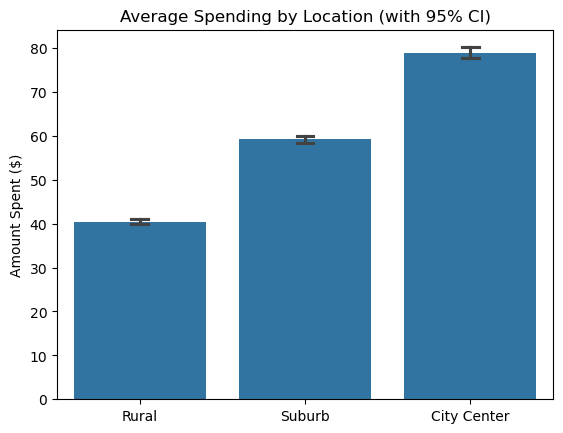

In [72]:
# 1. Spending by location — mean with confidence intervals, annotated against MDE
sns.barplot(
            data=df, 
            x="Store_Location",
            y="Amount_Spent", 
            order=["Rural", "Suburb", "City Center"],
            errorbar="ci", 
            capsize=0.1
            )

plt.title("Average Spending by Location (with 95% CI)")
plt.ylabel("Amount Spent ($)")
plt.xlabel(None)

plt.show()

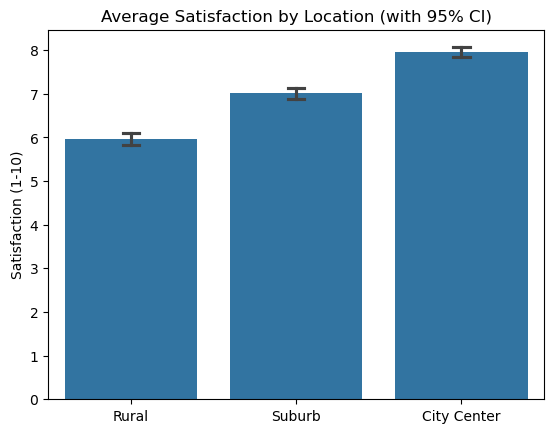

In [74]:
# 2. Satisfaction by location — mean with confidence intervals
sns.barplot(
            data=df, 
            x="Store_Location", 
            y="Customer_Satisfaction",
            order=["Rural", "Suburb", "City Center"], errorbar="ci", capsize=0.1
            )

plt.title("Average Satisfaction by Location (with 95% CI)")
plt.xlabel(None)
plt.ylabel("Satisfaction (1-10)")
plt.show()

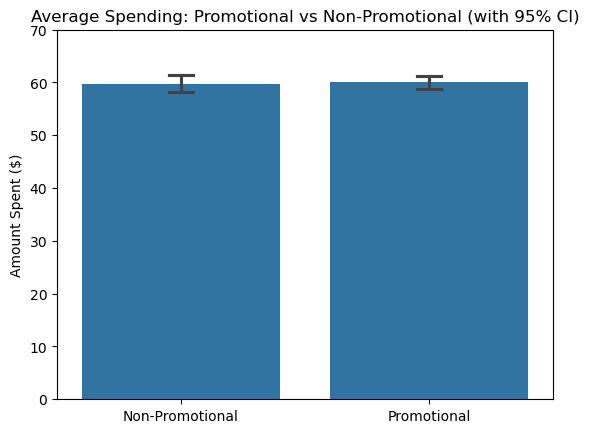

In [76]:
# 3. Promotional vs Non-Promotional — showing the near-identical means
sns.barplot(
    data=df, 
    x="Purchase_Type", 
    y="Amount_Spent", 
    errorbar="ci", 
    capsize=0.1
    )

plt.title("Average Spending: Promotional vs Non-Promotional (with 95% CI)")
plt.xlabel(None)
plt.ylabel("Amount Spent ($)")
plt.ylim(0, 70)  # zoom in so the (lack of) difference is visible, not hidden by a tall axis
plt.show()

### Part 5: Reflection

Discuss:
1. The strengths and limitations of your analysis
2. Any assumptions or potential biases in the data
3. Suggestions for additional data collection
4. How this analysis could be improved

**Reflective Question: Explain the importance of experimental design and sufficient sample size in conducting a robust analysis. Identify any limitations in the dataset or analysis (e.g., potential biases, unmeasured variables) and suggest additional data the company could collect to improve future analyses.**

### Part 5: Reflection

**On experimental design and sample size:**

*A well-designed experiment matters just as much as the statistical test itself. Having the MDEs before running any tests (15% for spending, 1.0 point for satisfaction, $15 for promotional lift) meant I had a clear line for what counted as "worth acting on," rather than rationalizing whatever number came out afterward. This mattered concretely in this analysis: the promotional spending test had a large enough sample (612 vs 888) to detect even a tiny effect if one existed, and it still came back null — that's a meaningful null result. Sample size also let me lean on the Central Limit Theorem when normality was violated for the promo comparison*

**Limitations and potential biases in the dataset:**

- **Independence couldn't be verified.** *I assumed each row is an independent transaction, but the data doesn't show a customer ID, so I can't confirm whether the same customer appears multiple times. If a small group of repeat customers accounts for a large share of the rows, that would violate independence and could bias the results especially for location and satisfaction.*

- **No time dimension.** *The data doesn't show when each transaction happened. For the promotional analysis in particular, I don't know how long promotions ran, how frequently, or whether "Promotional" rows are concentrated in specific periods (e.g., holidays) that could confound the comparison. A null result today might look different with time controlled for.*

- **No demographic data.** *I found a large spending and satisfaction gap by location but have no way to explain why — income level, age, or customer tenure could all be driving the difference, and without that data I can only describe the pattern, not diagnose its cause.*

- **No MDE for product category preference.** *This was flagged back in Part 1.1 — without a predefined threshold, I can only say the association was statistically negligible (Cramer's V = 0.040), not whether some smaller-than-expected association would have still mattered to the business.*

**Additional data the company could collect:**

- A customer ID (even anonymized) to check for repeat visits and properly account for non-independence.
- Timestamps for each transaction, and start/end dates for promotional periods, to separate promotional timing effects from promotional presence effects.
- Basic demographic or loyalty-tier data, to help explain the location-driven differences rather than just describe them.
- Promotion type/depth (e.g., % discount, BOGO, flat dollar off),since "Promotional" here is a single catch-all category that may be masking very different strategies with different results.

**How this analysis could be improved:**

With the additional data above, this could move from associational to more diagnostic — for example, running a regression controlling for time period and customer tenure to isolate the true effect of location, rather than relying on a location comparison that could partly reflect who happens to shop there. I'd also want to re-run the promotional analysis broken down by promotion type once that data exists, since a single non-significant result across all promotions could still be hiding a working prSomotion type diluted by a non-working one.